In [1]:
import pandas as pd 
import numpy as np  
import yfinance as yf

## 1. Download and clean the data

In [2]:
# Download daily adjusted prices.
stk_data = yf.download("TATACONSUM.NS", start="2021-06-01", end="2022-01-05") 

[*********************100%***********************]  1 of 1 completed


In [3]:
# Check whether the column names have multiple levels. Ex:("Close", "TATACONSUM.NS")
if stk_data.columns.nlevels > 1:
    stk_data.columns = stk_data.columns.get_level_values(0)  # Keep only the first level: Close, High, Low, Open, Volume.

In [4]:
# Keep OHLC prices in date order.
stk_data = stk_data[["Open", "High", "Low", "Close"]].sort_index()  # Keep OHLC prices in date order.

In [5]:
# Select Close column
column = "Close"

In [6]:
close = stk_data["Close"].diff().dropna()

In [7]:
close

Date
2021-06-02     7.393188
2021-06-03     6.153076
2021-06-04     6.630127
2021-06-07    12.401672
2021-06-08    10.016724
                ...    
2021-12-29    -0.287842
2021-12-30     1.295227
2021-12-31    14.823242
2022-01-03     4.365356
2022-01-04    -8.778809
Name: Close, Length: 149, dtype: float64

## 2. Split into training and test sets

In [8]:
training_size = int(len(close) * 0.80)  # Find the position of the 80% split.

train = close.iloc[:training_size]  # Use earlier observations to train the model.
test = close.iloc[training_size:]  # Reserve later observations for the final evaluation.

print("Training rows:", len(train))
print("Test rows:", len(test))

Training rows: 119
Test rows: 30


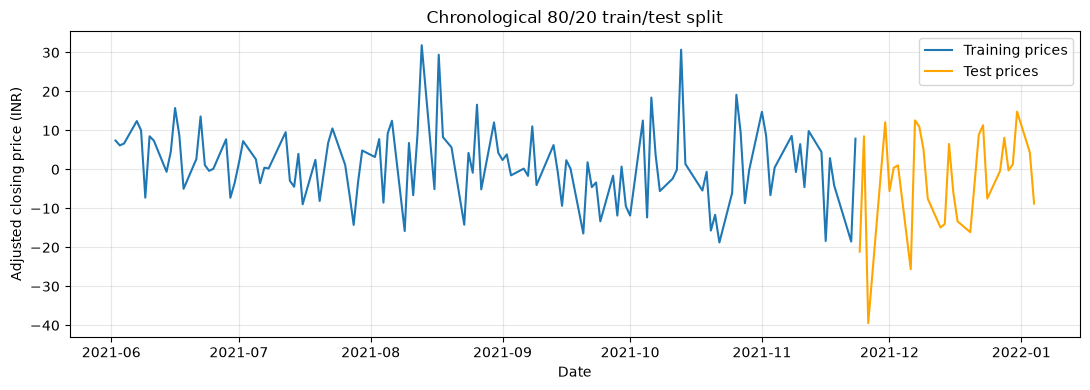

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(11, 4))  # Create a plot for the chronological split.
plt.plot(train.index, train, label="Training prices")  # Plot the earlier prices.
plt.plot(test.index, test, label="Test prices", color="orange")  # Plot the held-out prices.
plt.title("Chronological 80/20 train/test split")  # Add a descriptive title.
plt.xlabel("Date")  # Label the horizontal axis.
plt.ylabel("Adjusted closing price (INR)")  # Label the price units.
plt.legend()  # Identify each line.
plt.grid(alpha=0.3)  # Add a light grid.
plt.tight_layout()  # Adjust spacing around the plot.
plt.show()  # Display the plot.

## 3. Test stationarity with adfuller

In [10]:
from statsmodels.tsa.stattools import adfuller  # Import the ADF test.

close = stk_data["Close"].diff().dropna()  # Calculate first differences and remove the initial missing value.
result = adfuller(close, autolag="AIC")  # Run the ADF test and select the lag length using AIC.

print("ADF Statistic:", result[0])  # Display the test statistic.
print("p-value:", result[1])  # Display the p-value.

ADF Statistic: -12.354658143589564
p-value: 5.722219299694423e-23


/var/folders/tk/w8w2mxns4s16myv7xnc6y6z40000gp/T/ipykernel_98191/2778532910.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(close, autolag="AIC")  # Run the ADF test and select the lag length using AIC.


## 4. Create the model and forecast

In [11]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(train.to_numpy(), order=(1, 0, 1))  # Create an ARMA(1,1) model without a date index.
model_fit = model.fit()  # Fit the model again using training data.

print(model_fit.summary())

/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  119
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -437.320
Date:                Wed, 28 Oct 2026   AIC                            882.641
Time:                        13:53:44   BIC                            893.757
Sample:                             0   HQIC                           887.155
                                - 119                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.2792      0.891      1.435      0.151      -0.468       3.026
ar.L1         -0.2321      3.985     -0.058      0.954      -8.042       7.577
ma.L1          0.2128      4.029      0.053      0.9

In [12]:
forecast_values = model_fit.forecast(steps=len(test))  # Forecast one value per test observation.
predictions = pd.Series(np.asarray(forecast_values), index=test.index)  # Attach the held-out trading dates.

print(predictions.head())  # Display the first five forecasts.

Date
2021-11-24    1.076108
2021-11-25    1.326288
2021-11-26    1.268215
2021-11-29    1.281695
2021-11-30    1.278566
dtype: float64


## 5. Calculate MSE, RMSE, and R²

In [13]:
from sklearn.metrics import mean_squared_error, r2_score

# Calculate the average squared forecast error.
mse = mean_squared_error(test, predictions) 

# Calculate RMSE without the unsupported squared=False argument.
rmse = np.sqrt(mse) 

# Calculate the coefficient of determination on unseen data.
r2 = r2_score(test, predictions)

print("Test MSE:", mse)  
print("Test RMSE:", rmse)  
print("Test R2 score:", r2) 

Test MSE: 170.06971484619987
Test RMSE: 13.041077978687186
Test R2 score: -0.09598392813575773


In [14]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, r2_score  
import numpy as np  

for p in range(1, 6):  # Try autoregressive orders from 1 to 5.
    for q in range(1, 6):  # Try moving-average orders from 1 to 5.
        try:  # Attempt to fit and evaluate this model.
            model = ARIMA(train.to_numpy(), order=(p, 0, q))  # Remove the date index to avoid the frequency warning.
            model_fit = model.fit()  # Fit the model using training observations.
            predictions = model_fit.forecast(steps=len(test))  # Forecast one value per test observation.
            rmse = np.sqrt(mean_squared_error(test, predictions))  # Calculate RMSE.
            r2 = r2_score(test, predictions)  # Calculate R-squared.
            print(f"ARMA({p},{q}) RMSE={rmse:.4f} R2={r2:.4f}")  # Display the scores.
        except Exception as error:  # Catch errors for this model combination.
            print(f"ARMA({p},{q}) failed: {error}")  # Show errors instead of silently hiding them.

ARMA(1,1) RMSE=13.0411 R2=-0.0960


/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARMA(1,2) RMSE=12.9119 R2=-0.0744
ARMA(1,3) RMSE=12.9268 R2=-0.0769


/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARMA(1,4) RMSE=12.9903 R2=-0.0875
ARMA(1,5) RMSE=12.7332 R2=-0.0449
ARMA(2,1) RMSE=12.9100 R2=-0.0741
ARMA(2,2) RMSE=13.2718 R2=-0.1351


...

/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARMA(4,5) RMSE=13.2668 R2=-0.1343
ARMA(5,1) RMSE=12.7474 R2=-0.0472
ARMA(5,2) RMSE=13.0190 R2=-0.0923


/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


ARMA(5,3) RMSE=12.5382 R2=-0.0131
ARMA(5,4) RMSE=12.7227 R2=-0.0431
ARMA(5,5) RMSE=13.5474 R2=-0.1827


/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


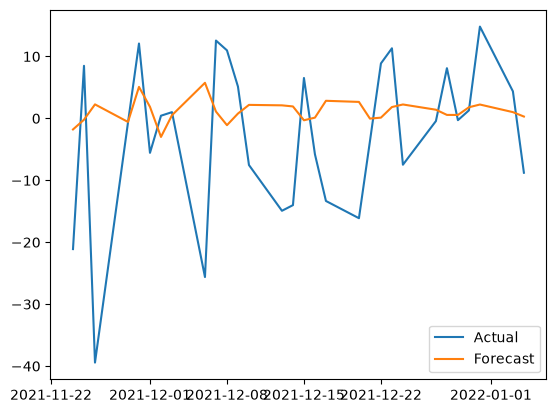

In [15]:
plt.plot(test.index, test, label="Actual")  # Plot actual test values.
plt.plot(test.index, predictions, label="Forecast")  # Attach test dates to the forecast values.
plt.legend()  # Display the line labels.
plt.show()  # Display the plot.